# Notebook 02: Baseline model

**Goal:** train a first, simple sentiment model and measure honestly how good it is.

**Input:** `data/processed/reviews_electronics_clean.csv` (made by notebook 01)
**Output:** a saved model in `models/` and a set of evaluation results

**What we do, in order**
1. Split the data into a training set and a test set
2. Turn text into numbers (TF-IDF)
3. Train a classifier (Logistic Regression)
4. Evaluate with precision, recall and F1
5. Compare with a "lazy guesser" to prove the model learned something
6. Study the mistakes (error analysis)
7. See which words the model relies on
8. Save the model

A **baseline** is a simple model that gives us a reference score. Later models (Naive Bayes, SVM, a transformer) must beat it to be worth using.

## Step 0: Setup

In [1]:
import os, sys
root = os.getcwd() if os.path.isdir("src") else os.path.abspath("..")
os.chdir(root)
sys.path.insert(0, root)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, accuracy_score, f1_score)
import joblib

pd.set_option("display.max_colwidth", 100)

## Step 1: Load the cleaned data

In [2]:
elec = pd.read_csv("data/processed/reviews_electronics_clean.csv")
elec = elec.dropna(subset=["clean_text"])
print(elec.shape)
elec[["Summary", "clean_text", "label"]].head()

(67401, 9)


,Summary,clean_text,label
0,great cooler excellent air flow and for this price its so amazing and unbelievablejust love it,great cooler excellent air flow price amaze unbelievablejust love,positive
1,best budget 2 fit cooler nice cooling,best budget fit cooler nice cool,positive
2,the quality is good but the power of air is decent,quality good but power air decent,neutral
3,very bad product its a only a fan,very bad product fan,negative
4,ok ok product,ok ok product,neutral


## Step 2: Split into training and test sets

We hide 20% of the reviews from the model and use them only for scoring. If we scored the model on reviews it trained on, it could just memorise them.

- `stratify=elec["label"]` keeps the same class mix (about 78% / 15% / 7%) in both parts, so the rare *neutral* class is not accidentally missing from the test set.
- `random_state=42` makes the split repeatable, so you get the same numbers every time.

**Extra check: the "strict" test set.** Many reviews are just "good" or "nice", and the same text appears in both train and test. That is not cheating (each review has its own label) but it makes scores optimistic. So we also keep a **strict test set**: only test reviews whose exact text never appeared in training. If the score is similar on both, the model is not just memorising repeated phrases.

In [3]:
train, test = train_test_split(elec, test_size=0.2,
                               stratify=elec["label"], random_state=42)
print("train:", len(train), " test:", len(test))
print("class mix in train:\n", train["label"].value_counts(normalize=True).round(3))
print("class mix in test:\n", test["label"].value_counts(normalize=True).round(3))

seen_texts = set(train["clean_text"])
strict_test = test[~test["clean_text"].isin(seen_texts)]
print("strict test size:", len(strict_test), "of", len(test))

train: 53920  test: 13481
class mix in train:
 label
positive    0.778
negative    0.147
neutral     0.075
Name: proportion, dtype: float64
class mix in test:
 label
positive    0.778
negative    0.147
neutral     0.075
Name: proportion, dtype: float64
strict test size: 7621 of 13481


## Step 3: Turn text into numbers with TF-IDF

A model cannot read words, only numbers. **TF-IDF** turns every review into a row of numbers, one number per word in the vocabulary:

- **TF** (term frequency): how often the word appears in this review
- **IDF** (inverse document frequency): how rare the word is across all reviews. Common words like "product" get low weight, distinctive words like "refund" get higher weight.

Settings:
- `ngram_range=(1, 2)`: use single words *and* word pairs. The pair "not good" becomes its own feature, which is how a simple model can handle negation.
- `min_df=3`: ignore words that appear in fewer than 3 reviews (mostly typos).
- `max_features=50000`: keep at most the 50,000 most useful words and pairs.

**Important rule:** `fit_transform` on the training data *learns* the vocabulary. On the test data we only use `transform`. If the test data helped build the vocabulary, information would leak.

In [4]:
vec = TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_features=50000)
X_train = vec.fit_transform(train["clean_text"])   # learn vocabulary from TRAIN only
X_test = vec.transform(test["clean_text"])         # only apply it to TEST
X_strict = vec.transform(strict_test["clean_text"])
print("training matrix (reviews x features):", X_train.shape)

training matrix (reviews x features): (53920, 23287)


## Step 4: Train the classifier

**Logistic Regression** learns a weight for every word or word pair: positive weights push a review toward a class, negative weights push away. It is fast and easy to explain, which is why it is a good baseline.

`class_weight="balanced"` tells the model that mistakes on the rare classes (negative, neutral) cost more. Without it, the model would be tempted to say "positive" for almost everything, because 78% of reviews are positive.

In [5]:
clf = LogisticRegression(max_iter=1000, class_weight="balanced")
clf.fit(X_train, train["label"])
print("trained. classes:", list(clf.classes_))

trained. classes: ['negative', 'neutral', 'positive']


## Step 5: Evaluate

How to read the report:
- **Precision:** of the reviews the model *called* a class, how many truly were that class.
- **Recall:** of the reviews that truly *are* a class, how many the model found.
- **F1:** one number that combines precision and recall.
- **macro avg:** the plain average of the three classes' F1. Each class counts equally, so it is the fair headline number here.

**Why not just accuracy?** About 78% of the test set is positive. A model that always answers "positive" would already score about 78% accuracy while being useless. That is why we report macro-F1.

In [6]:
pred = clf.predict(X_test)
print("=== Normal test set ===")
print(classification_report(test["label"], pred, digits=3))

pred_strict = clf.predict(X_strict)
print("=== Strict test set (texts never seen in training) ===")
print(classification_report(strict_test["label"], pred_strict, digits=3))

=== Normal test set ===
              precision    recall  f1-score   support

    negative      0.800     0.830     0.814      1986
     neutral      0.199     0.500     0.285      1008
    positive      0.957     0.811     0.878     10487

    accuracy                          0.791     13481
   macro avg      0.652     0.714     0.659     13481
weighted avg      0.877     0.791     0.824     13481

=== Strict test set (texts never seen in training) ===
              precision    recall  f1-score   support

    negative      0.761     0.815     0.787      1413
     neutral      0.227     0.450     0.301       607
    positive      0.954     0.835     0.891      5601

    accuracy                          0.801      7621
   macro avg      0.647     0.700     0.660      7621
weighted avg      0.860     0.801     0.825      7621



**What to notice:** positive and negative are scored well. **Neutral is much weaker**: the model finds about half of the real neutral reviews, but most reviews it calls neutral are not. That is partly the model's fault and partly the label noise from Notebook 01 (identical text, different stars).

## Step 6: Is the model better than a lazy guesser?

A `DummyClassifier` that always predicts the most common class gives us a floor. Our model should clearly beat it on macro-F1.

In [7]:
dummy = DummyClassifier(strategy="most_frequent").fit(X_train, train["label"])
dummy_pred = dummy.predict(X_test)

rows = []
for name, p in [("Always 'positive'", dummy_pred), ("TF-IDF + Logistic Regression", pred)]:
    rows.append({"model": name,
                 "accuracy": round(accuracy_score(test["label"], p), 3),
                 "macro_F1": round(f1_score(test["label"], p, average="macro"), 3)})
pd.DataFrame(rows)

,model,accuracy,macro_F1
0,Always 'positive',0.778,0.292
1,TF-IDF + Logistic Regression,0.791,0.659


**What to notice:** the lazy guesser's *accuracy* looks decent, but its *macro-F1* is poor. Our model is much better on macro-F1. This is the clearest proof that the model learned something real.

## Step 7: Confusion matrix

Each **row** is the true label and each **column** is what the model predicted. The diagonal (top-left to bottom-right) shows correct answers. Numbers off the diagonal are mistakes: look at where the neutral row and column leak.

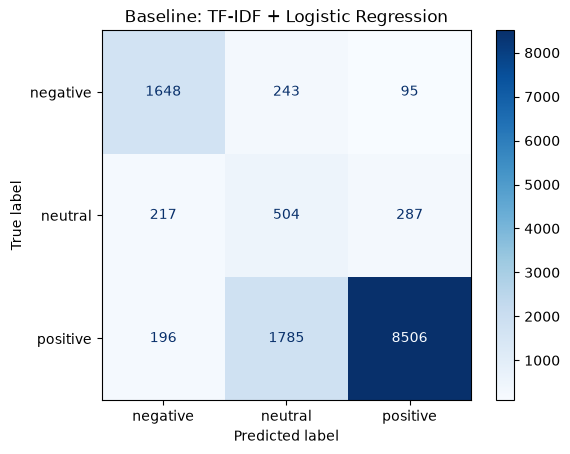

In [8]:
labels = ["negative", "neutral", "positive"]
cm = confusion_matrix(test["label"], pred, labels=labels)
ConfusionMatrixDisplay(cm, display_labels=labels).plot(cmap="Blues", values_format="d")
plt.title("Baseline: TF-IDF + Logistic Regression")
plt.show()

## Step 8: Error analysis (read real mistakes)

Numbers tell us *how many* mistakes; reading examples tells us *why*. Look at the reviews below and write down 2 or 3 patterns (short generic text? mixed feelings like "good but..."? sarcasm?). This is the heart of a good project discussion.

In [9]:
test = test.copy()
test["pred"] = pred

def show_examples(rows, n=10):
    """Show up to n random rows (fewer if there are not that many)."""
    display(rows.sample(min(n, len(rows)), random_state=1)[["Summary", "Rate", "pred"]])

print("TRUE neutral, but the model said something else:")
show_examples(test[(test.label == "neutral") & (test.pred != "neutral")])

print("TRUE positive, but the model said neutral:")
show_examples(test[(test.label == "positive") & (test.pred == "neutral")])

TRUE neutral, but the model said something else:


,Summary,Rate,pred
35660,signal is not that good in 2bhk house,3.0,negative
51870,nice product,3.0,positive
14550,nyc,3.0,positive
20535,best laptop in best price but battery backup is lower expect battery backup everything is superb...,3.0,positive
50578,nice oneand delivery also good but its over heating but its very easy to clean with this portabl...,3.0,positive
44453,battery is not working for long battery is getting low within 30 minutes,3.0,negative
55392,heat issue ok to buy the product i will recommend,3.0,negative
38715,value for money,3.0,positive
20018,pros great performance boots up in 8 seconds can play most games in high settings the rgb keyboa...,3.0,positive
65078,i am not happy with the heat and grilling time,3.0,negative


TRUE positive, but the model said neutral:


,Summary,Rate,pred
2961,good,5.0,neutral
37204,super product all functions okay,5.0,neutral
49539,you cant expect more than this at this price,4.0,neutral
26509,nice,4.0,neutral
42066,good very beautiful,5.0,neutral
48046,this product is a very good but wi fi dongle nhi ha iska sath,5.0,neutral
37772,nicebut because of covid no demo,4.0,neutral
50565,its a good product build quality is good no blower is there cord lenght is good attachment are e...,4.0,neutral
8641,good,4.0,neutral
19530,good,4.0,neutral


## Step 9: Which words does the model rely on?

For each class, these are the words and word pairs with the strongest positive weight. Check that sensible negations (like "not work") show up under *negative*. That shows the word-pair features handle negation, and why we kept "not" in preprocessing.

In [10]:
features = np.array(vec.get_feature_names_out())
for i, class_name in enumerate(clf.classes_):
    top = np.argsort(clf.coef_[i])[-12:][::-1]
    print(f"{class_name:9s}:", ", ".join(features[top]))

negative : not, worst, waste, poor, useless, stop, return, bad, disappoint, not work, horrible, unable
neutral  : not, backup issue, goodbut, sound bass, give star, okay, no bad, bass effect, average, one go, but, charger work
positive : not bad, love, great, very useful, easy, budget, wonderful, best, no issue, fantastic, well, awesome


## Step 10: Save the model

We save the vectorizer and the classifier together, so the app can load them later and score new reviews. (Model files are ignored by Git.)

In [11]:
os.makedirs("models", exist_ok=True)
joblib.dump((vec, clf), "models/baseline_tfidf_lr.pkl")
print("saved models/baseline_tfidf_lr.pkl")

saved models/baseline_tfidf_lr.pkl


## Results from our run (baseline)

| Test set | Accuracy | Macro-F1 | Negative F1 | Neutral F1 | Positive F1 |
|---|---|---|---|---|---|
| Normal (13,481 reviews) | 0.791 | 0.659 | 0.814 | 0.285 | 0.878 |
| Strict (7,621 reviews) | 0.801 | 0.660 | 0.787 | 0.301 | 0.891 |

Your numbers should match closely if you keep `random_state=42`.

**Takeaways:** the model clearly beats the always-positive baseline on macro-F1; scores are the same on the strict set, so it is not just memorising repeated phrases; neutral is the weak class.

**Next:** compare Naive Bayes and Linear SVM, try to improve neutral, then a transformer model.